In [26]:
from astropy import units as u
from astropy import time

import numpy as np

from poliastro import iod
from poliastro.bodies import Earth, Jupiter, Sun
from poliastro.ephem import Ephem
from poliastro.maneuver import Maneuver
from poliastro.twobody import Orbit
from poliastro.util import time_range

In [27]:
# More info: https://plotly.com/python/renderers/
import plotly.io as pio

pio.renderers.default = "plotly_mimetype+notebook_connected"

In [28]:
from astropy.coordinates import solar_system_ephemeris

solar_system_ephemeris.set("jpl")

<ScienceState solar_system_ephemeris: 'jpl'>

In [29]:
# Initial data
date_launch = time.Time("2024-08-17 00:00", scale="utc").tdb
date_arrival = time.Time("2027-05-11 05:17", scale="utc").tdb

c:\src\ASEN5053\project\python\.conda\lib\site-packages\erfa\core.py:154: ErfaWarning:

ERFA function "dtf2d" yielded 1 of "dubious year (Note 6)"

c:\src\ASEN5053\project\python\.conda\lib\site-packages\erfa\core.py:154: ErfaWarning:

ERFA function "utctai" yielded 1 of "dubious year (Note 3)"

c:\src\ASEN5053\project\python\.conda\lib\site-packages\erfa\core.py:154: ErfaWarning:

ERFA function "taiutc" yielded 1 of "dubious year (Note 4)"



In [30]:
earth = Ephem.from_body(Earth, time_range(date_launch, end=date_arrival))
jupiter = Ephem.from_body(Jupiter, time_range(date_launch, end=date_arrival))
# Solve for departure and target orbits
ss_earth = Orbit.from_ephem(Sun, earth, date_launch)
ss_jupiter = Orbit.from_ephem(Sun, jupiter, date_arrival)

In [31]:
# Solve for the transfer maneuver
man_lambert = Maneuver.lambert(ss_earth, ss_jupiter)

# Get the transfer and final orbits
ss_trans, ss_target = ss_earth.apply_maneuver(man_lambert, intermediate=True)

In [32]:
from poliastro.plotting import OrbitPlotter3D
plotter = OrbitPlotter3D()
plotter.set_attractor(Sun)

plotter.plot_ephem(earth, date_launch, label="Earth at launch position")
plotter.plot_ephem(jupiter, date_arrival, label="Jupiter at arrival position", color="purple")
plotter.plot_ephem(earth, date_arrival, label="Earth at arrival position")
plotter.plot_ephem(jupiter,date_launch,label="Jupiter at launch position", color="orange")
plotter.plot_trajectory(
    ss_trans.sample(max_anomaly=180 * u.deg),
    color="black",
    label="Transfer orbit",
)
plotter.set_view(45 * u.deg, 260 * u.deg, distance=3* u.km)

C:\Users\aussiebuttz\AppData\Local\Temp\ipykernel_26132\1577612030.py:10: DeprecationWarning:

Specifying min_anomaly and max_anomaly in method `sample` is deprecated and will be removed in a future release, use `Orbit.to_ephem(strategy=TrueAnomalyBounds(min_nu=..., max_nu=...))` instead



C:\Users\aussiebuttz\AppData\Local\Temp\ipykernel_26132\2220509351.py:15: DeprecationWarning:

Specifying min_anomaly and max_anomaly in method `sample` is deprecated and will be removed in a future release, use `Orbit.to_ephem(strategy=TrueAnomalyBounds(min_nu=..., max_nu=...))` instead



([<matplotlib.lines.Line2D at 0x1df2e3017c0>], None)

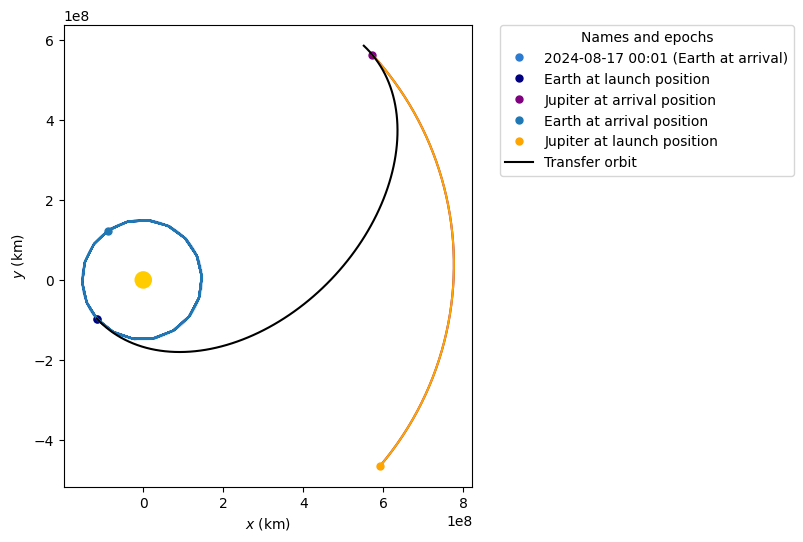

In [34]:
from poliastro.plotting import StaticOrbitPlotter

plotter = StaticOrbitPlotter()
plotter.plot_body_orbit(
    Earth,
    date_launch,
    label="Earth at arrival",
    trail=True,
)
plotter.plot_ephem(earth, date_launch, label="Earth at launch position", color="navy")
plotter.plot_ephem(jupiter, date_arrival, label="Jupiter at arrival position", color="purple")
plotter.plot_ephem(earth, date_arrival, label="Earth at arrival position")
plotter.plot_ephem(jupiter,date_launch,label="Jupiter at launch position", color="orange")
plotter.plot_trajectory(
    ss_trans.sample(max_anomaly=180 * u.deg),
    color="black",
    label="Transfer orbit",
)
# plotter.set_view(45 * u.deg, 260 * u.deg, distance=3* u.km)